In [16]:
%load_ext autoreload
%autoreload 2
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support

sys.path.insert(0, os.path.abspath('..'))

import config
from src.model import train_catboost, train_xgboost, train_lightgbm
from src.evaluation import evaluate_performance, display_mod_performance, get_pr_curve
from src.mrm import score_deciles, get_gains
from src.experiment import log_run, load_experiment_log

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
X_train = pd.read_parquet(config.RESULTS_PATH / 'X_train.parquet')
X_val   = pd.read_parquet(config.RESULTS_PATH / 'X_val.parquet')
X_test  = pd.read_parquet(config.RESULTS_PATH / 'X_test.parquet')
y_train = pd.read_parquet(config.RESULTS_PATH / 'y_train.parquet')[config.TARGET]
y_val   = pd.read_parquet(config.RESULTS_PATH / 'y_val.parquet')[config.TARGET]
y_test  = pd.read_parquet(config.RESULTS_PATH / 'y_test.parquet')[config.TARGET]

print(f'X_train: {X_train.shape}')
print(f'X_val:   {X_val.shape}')
print(f'X_test:  {X_test.shape}')

cat_features = [c for c in X_train.columns if c.endswith('_encoded')]
print(f'cat_features: {len(cat_features)}')

X_train: (413378, 431)
X_val:   (88581, 431)
X_test:  (88581, 431)
cat_features: 26


## catboost

In [3]:
cat_model = train_catboost(X_train, y_train, X_val, y_val, cat_features)
print(f'best iteration: {cat_model.get_best_iteration()}')

cat_proba = cat_model.predict_proba(X_val)[:, 1]
cat_preds = (cat_proba > 0.5).astype(int)
cat_auc = roc_auc_score(y_val.values, cat_proba)
cat_pr_auc = average_precision_score(y_val.values, cat_proba)
cat_p, cat_r, cat_f1, _ = precision_recall_fscore_support(y_val.values, cat_preds, average='binary')

log_run(
    model_name='catboost_full_features',
    params={
        'model_type': 'catboost',
        'iterations': cat_model.get_best_iteration(),
        'learning_rate': 0.05,
        'depth': 6,
        'n_features': X_train.shape[1],
        'feature_set': 'full',
    },
    metrics={
        'val_auc': round(float(cat_auc), 5),
        'val_gini': round(float(2 * cat_auc - 1), 5),
        'val_pr_auc': round(float(cat_pr_auc), 5),
        'val_precision': round(float(cat_p), 5),
        'val_recall': round(float(cat_r), 5),
        'val_f1': round(float(cat_f1), 5),
    },
    results_path=config.RESULTS_PATH,
)

0:	test: 0.7148670	best: 0.7148670 (0)	total: 750ms	remaining: 12m 29s
100:	test: 0.8662124	best: 0.8662124 (100)	total: 55.1s	remaining: 8m 10s
200:	test: 0.8796923	best: 0.8796923 (200)	total: 1m 53s	remaining: 7m 32s
300:	test: 0.8855907	best: 0.8855907 (300)	total: 2m 56s	remaining: 6m 49s
400:	test: 0.8896259	best: 0.8896453 (399)	total: 3m 55s	remaining: 5m 51s
500:	test: 0.8928416	best: 0.8928416 (500)	total: 4m 55s	remaining: 4m 54s
600:	test: 0.8958373	best: 0.8958373 (600)	total: 5m 55s	remaining: 3m 55s
700:	test: 0.8997866	best: 0.8997866 (700)	total: 6m 54s	remaining: 2m 56s
800:	test: 0.9021833	best: 0.9022666 (797)	total: 7m 54s	remaining: 1m 57s
900:	test: 0.9040955	best: 0.9040955 (900)	total: 8m 54s	remaining: 58.7s
999:	test: 0.9061389	best: 0.9061389 (999)	total: 9m 53s	remaining: 0us

bestTest = 0.9061388802
bestIteration = 999

best iteration: 999
logged: catboost_full_features  val_auc=0.90614


## xgboost

In [4]:
xgb_model = train_xgboost(X_train, y_train, X_val, y_val)
print(f'best iteration: {xgb_model.best_iteration}')

xgb_proba = xgb_model.predict_proba(X_val)[:, 1]
xgb_preds = (xgb_proba > 0.5).astype(int)
xgb_auc = roc_auc_score(y_val.values, xgb_proba)
xgb_pr_auc = average_precision_score(y_val.values, xgb_proba)
xgb_p, xgb_r, xgb_f1, _ = precision_recall_fscore_support(y_val.values, xgb_preds, average='binary')

log_run(
    model_name='xgboost_full_features',
    params={
        'model_type': 'xgboost',
        'iterations': xgb_model.best_iteration,
        'learning_rate': 0.05,
        'max_depth': 6,
        'n_features': X_train.shape[1],
        'feature_set': 'full',
    },
    metrics={
        'val_auc': round(float(xgb_auc), 5),
        'val_gini': round(float(2 * xgb_auc - 1), 5),
        'val_pr_auc': round(float(xgb_pr_auc), 5),
        'val_precision': round(float(xgb_p), 5),
        'val_recall': round(float(xgb_r), 5),
        'val_f1': round(float(xgb_f1), 5),
    },
    results_path=config.RESULTS_PATH,
)

[0]	validation_0-auc:0.81603
[1]	validation_0-auc:0.83162
[2]	validation_0-auc:0.82808
[3]	validation_0-auc:0.82594
[4]	validation_0-auc:0.82924
[5]	validation_0-auc:0.83004
[6]	validation_0-auc:0.83078
[7]	validation_0-auc:0.83319
[8]	validation_0-auc:0.83437
[9]	validation_0-auc:0.83372
[10]	validation_0-auc:0.83809
[11]	validation_0-auc:0.83934
[12]	validation_0-auc:0.84348
[13]	validation_0-auc:0.84736
[14]	validation_0-auc:0.85053
[15]	validation_0-auc:0.85230
[16]	validation_0-auc:0.85386
[17]	validation_0-auc:0.85411
[18]	validation_0-auc:0.85478
[19]	validation_0-auc:0.85576
[20]	validation_0-auc:0.85747
[21]	validation_0-auc:0.85922
[22]	validation_0-auc:0.86060
[23]	validation_0-auc:0.86126
[24]	validation_0-auc:0.86136
[25]	validation_0-auc:0.86269
[26]	validation_0-auc:0.86319
[27]	validation_0-auc:0.86408
[28]	validation_0-auc:0.86445
[29]	validation_0-auc:0.86523
[30]	validation_0-auc:0.86657
[31]	validation_0-auc:0.86759
[32]	validation_0-auc:0.86795
[33]	validation_0-au

## lightgbm

In [ ]:
lgb_model = train_lightgbm(X_train, y_train, X_val, y_val)
print(f'best iteration: {lgb_model.best_iteration}')

lgb_proba = lgb_model.predict(X_val)
lgb_preds = (lgb_proba > 0.5).astype(int)
lgb_auc = roc_auc_score(y_val.values, lgb_proba)
lgb_pr_auc = average_precision_score(y_val.values, lgb_proba)
lgb_p, lgb_r, lgb_f1, _ = precision_recall_fscore_support(y_val.values, lgb_preds, average='binary')

log_run(
    model_name='lightgbm_full_features',
    params={
        'model_type': 'lightgbm',
        'iterations': lgb_model.best_iteration,
        'learning_rate': 0.05,
        'max_depth': 6,
        'n_features': X_train.shape[1],
        'feature_set': 'full',
    },
    metrics={
        'val_auc': round(float(lgb_auc), 5),
        'val_gini': round(float(2 * lgb_auc - 1), 5),
        'val_pr_auc': round(float(lgb_pr_auc), 5),
        'val_precision': round(float(lgb_p), 5),
        'val_recall': round(float(lgb_r), 5),
        'val_f1': round(float(lgb_f1), 5),
    },
    results_path=config.RESULTS_PATH,
)

logged: lightgbm_full_features  val_auc=0.91434


## experiment log

In [22]:
experiment_log = load_experiment_log(config.RESULTS_PATH)
display(experiment_log)

,timestamp,model,params.model_type,params.max_depth,params.class_weight,metrics.val_auc,metrics.val_gini,metrics.val_pr_auc,metrics.val_precision,metrics.val_recall,metrics.val_f1,params.iterations,params.learning_rate,params.depth,params.n_features,params.feature_set
0,2026-05-20T12:16:36.824918,xgboost_full_features,xgboost,6.0,NaN,0.91513,0.83026,0.55543,0.30799,0.67653,0.42328,639.0,0.05,NaN,431.0,full
1,2026-05-19T16:08:38.349038,xgboost_full_features,xgboost,6.0,NaN,0.91513,0.83026,0.55543,0.30799,0.67653,0.42328,639.0,0.05,NaN,431.0,full
2,2026-05-20T18:46:16.235199,lightgbm_full_features,lightgbm,6.0,NaN,0.91434,0.82868,0.53673,0.25093,0.71105,0.37095,411.0,0.05,NaN,431.0,full
3,2026-05-19T16:05:58.269367,catboost_full_features,catboost,NaN,NaN,0.90614,0.81228,0.56500,0.84202,0.34517,0.48962,999.0,0.05,6.0,431.0,full
4,2026-05-20T12:14:00.746645,catboost_full_features,catboost,NaN,NaN,0.90614,0.81228,0.56500,0.84202,0.34517,0.48962,999.0,0.05,6.0,431.0,full
5,2026-05-19T16:08:52.126909,lightgbm_full_features,lightgbm,6.0,NaN,0.82271,0.64543,0.28528,0.00000,0.00000,0.00000,1.0,0.05,NaN,431.0,full
6,2026-05-19T16:16:09.781070,lightgbm_full_features,lightgbm,6.0,NaN,0.82271,0.64543,0.28528,0.00000,0.00000,0.00000,1.0,0.05,NaN,431.0,full
7,2026-05-20T12:16:50.642495,lightgbm_full_features,lightgbm,6.0,NaN,0.82271,0.64543,0.28528,0.00000,0.00000,0.00000,1.0,0.05,NaN,431.0,full
8,2026-05-19T13:12:33.145894,baseline_decision_tree,decision_tree,10.0,balanced,0.80576,0.61152,0.35225,0.19668,0.62393,0.29909,NaN,NaN,NaN,NaN,NaN
9,2026-05-19T13:11:04.956103,baseline_decision_tree,decision_tree,10.0,balanced,0.80576,0.61152,0.35225,0.19668,0.62393,0.29909,NaN,NaN,NaN,NaN,NaN


## model comparison

In [23]:
import joblib

# load baseline model
baseline_model = joblib.load(config.OUTPUT_PATH / 'models' / 'baseline.pkl')
baseline_proba = baseline_model.predict_proba(X_val)[:, 1]

In [25]:
threshold = 0.8

df_scores = pd.DataFrame({
    'baseline_decision_tree': baseline_proba,
    'catboost_full_features': cat_proba,
    'xgboost_full_features': xgb_proba,
    'lightgbm_full_features': lgb_proba,
})

comparison = pd.DataFrame([
    evaluate_performance(df_scores, col, y_val.values, threshold=threshold)
    for col in df_scores.columns
]).sort_values('AUC', ascending=False).reset_index(drop=True)

display(comparison)

,Score,Precision,Recall,F1 Score,Accuracy,PR AUC,AUC,F2 Score,G-Mean,MCC,Gini
0,xgboost_full_features,0.66420,0.44214,0.53089,0.97317,0.55543,0.91513,0.47383,0.54191,0.52903,0.83026
1,lightgbm_full_features,0.60278,0.45595,0.51918,0.97100,0.53673,0.91434,0.47930,0.52425,0.50976,0.82868
2,catboost_full_features,0.93059,0.23800,0.37906,0.97322,0.56500,0.90614,0.27962,0.47062,0.46328,0.81228
3,baseline_decision_tree,0.34968,0.43590,0.38806,0.95279,0.35225,0.80576,0.41541,0.39042,0.36621,0.61152


## detailed evaluation -- best model

best model: xgboost_full_features


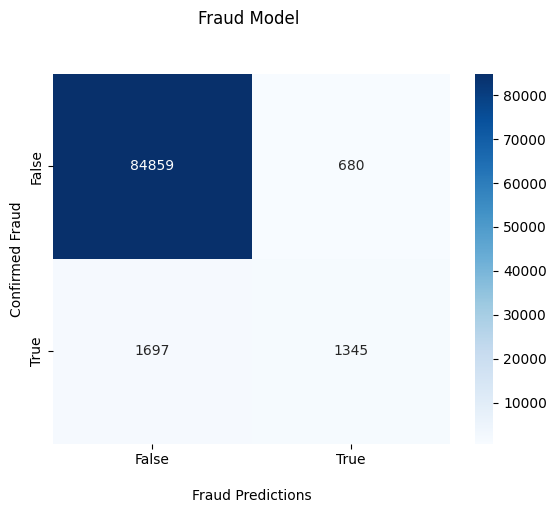

              precision    recall  f1-score   support

           0     0.9804    0.9921    0.9862     85539
           1     0.6642    0.4421    0.5309      3042

    accuracy                         0.9732     88581
   macro avg     0.8223    0.7171    0.7585     88581
weighted avg     0.9695    0.9732    0.9706     88581



In [26]:
score_col_map = {
    'baseline_decision_tree': baseline_proba,
    'catboost_full_features': cat_proba,
    'xgboost_full_features': xgb_proba,
    'lightgbm_full_features': lgb_proba,
}
best_name = comparison.iloc[0]['Score']
best_proba = score_col_map[best_name]
best_preds = (best_proba > threshold).astype(int)
print(f'best model: {best_name}')

display_mod_performance(
    y_val.values, best_preds,
    save_path=str(config.PLOTS_PATH / 'best_model_confusion_matrix.png'),
)

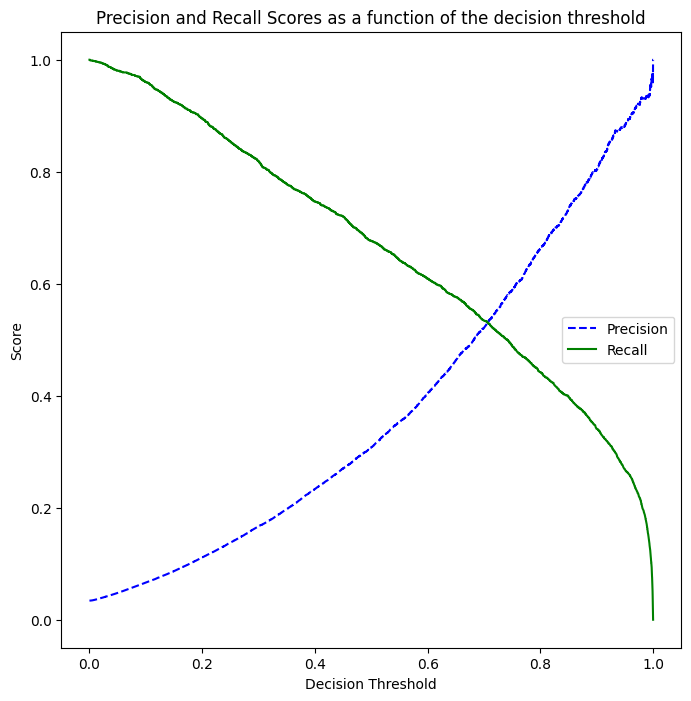

In [27]:
get_pr_curve(y_val.values, best_proba)
plt.savefig(str(config.PLOTS_PATH / 'best_model_pr_curve.png'), dpi=150, bbox_inches='tight')
plt.show()
plt.close()

In [28]:
df_best = pd.DataFrame({
    'TransactionID': range(len(y_val)),
    config.TARGET: y_val.values,
    'best_model_score': best_proba,
})

decile_table = score_deciles(
    df_best, uid='TransactionID', score='best_model_score', target=config.TARGET
)
display(decile_table)

% frauds captured in top decile: 0.7337


,n_events,best_model_score_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,0.425959,2232,2232,0.733728
2,8858,0.262685,335,2567,0.843853
3,8858,0.184580,188,2755,0.905654
4,8858,0.134409,92,2847,0.935897
5,8858,0.098268,75,2922,0.960552
6,8858,0.071058,44,2966,0.975016
7,8858,0.049664,16,2982,0.980276
8,8858,0.032127,28,3010,0.989481
9,8858,0.017076,18,3028,0.995398


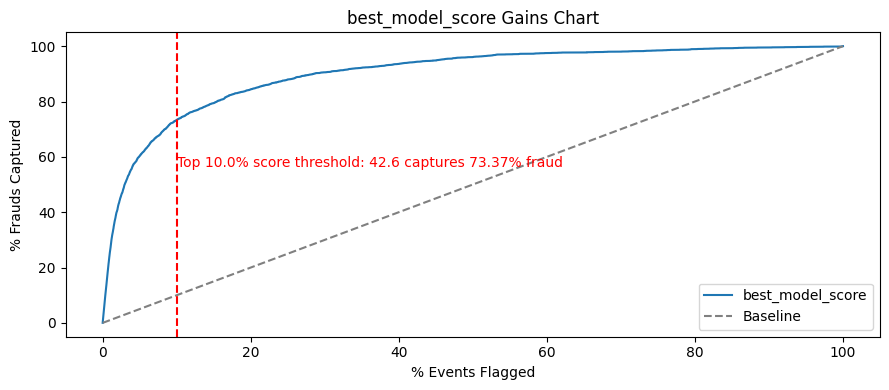

,index,threshold,pct_flagged,n_fraud_cap,fraud_pct_cap
0,best_model_score,0.425959,10.001016,2232.0,73.372781


In [29]:
get_gains(
    df_best, target=config.TARGET, score='best_model_score', top_n=0.1,
    save_path=str(config.PLOTS_PATH / 'best_model_gains.png'),
)

## feature importance

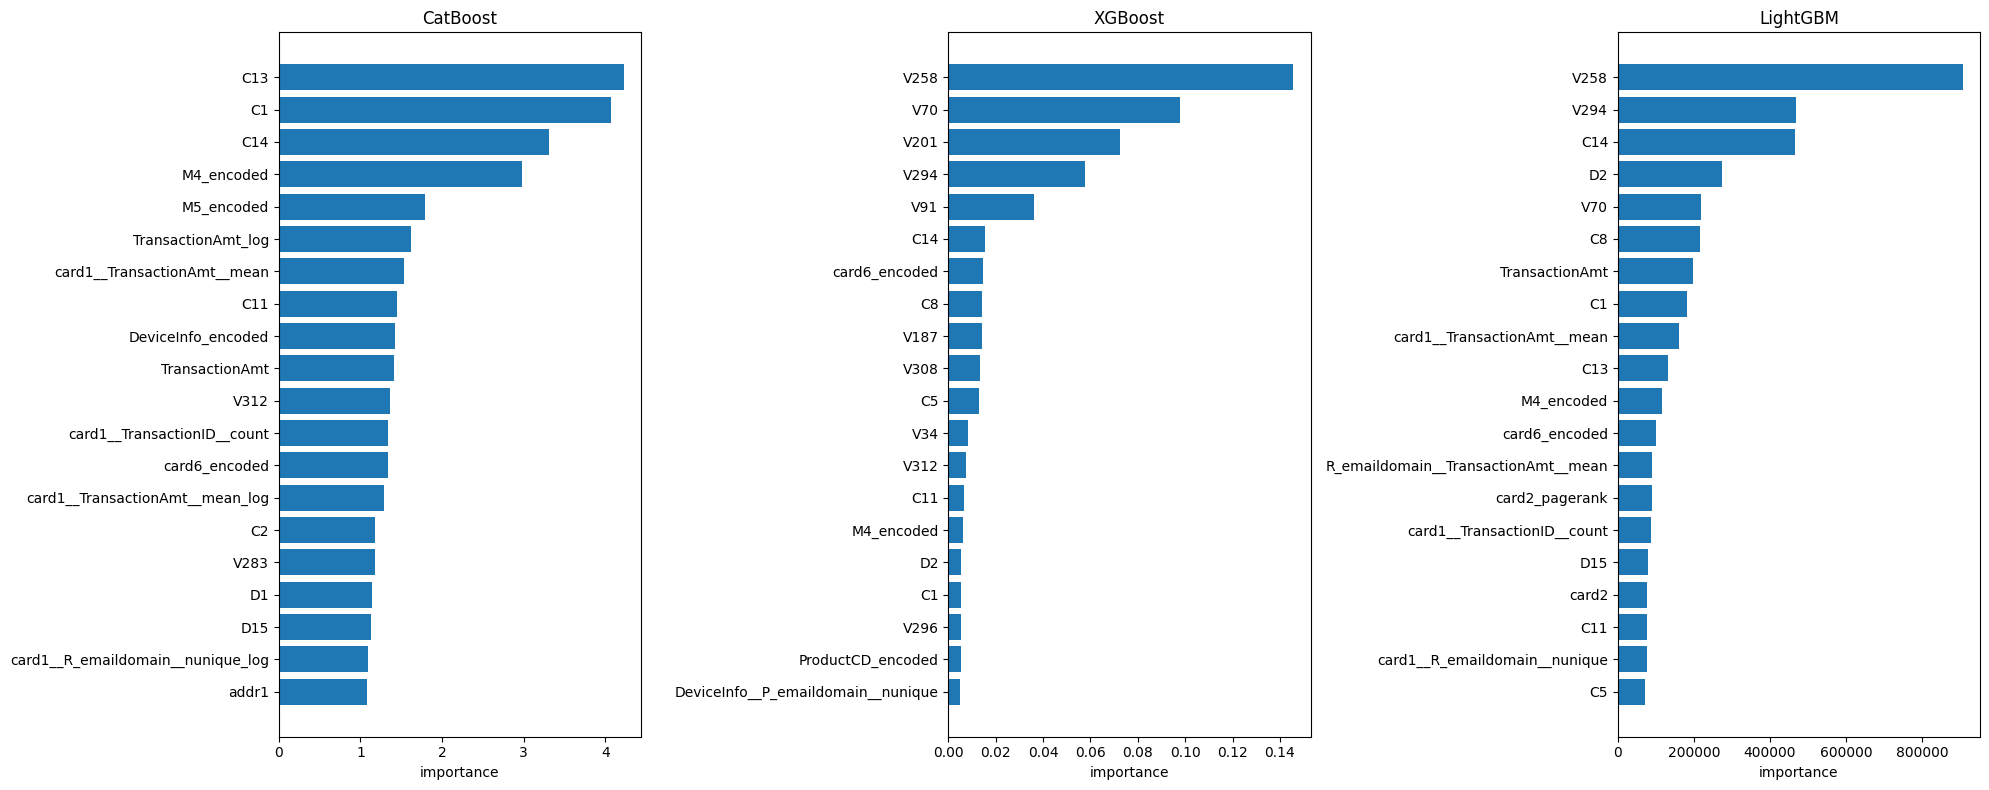

In [34]:
importances = {
    'CatBoost': pd.Series(cat_model.get_feature_importance(), index=X_train.columns),
    'XGBoost': pd.Series(xgb_model.feature_importances_, index=X_train.columns),
    'LightGBM': pd.Series(lgb_model.feature_importance(importance_type='gain'), index=X_train.columns),
}

fig, axes = plt.subplots(1, 3, figsize=(20, 8))
for ax, (name, imp) in zip(axes, importances.items()):
    top20 = imp.sort_values(ascending=False).head(20).sort_values()
    ax.barh(top20.index, top20.values)
    ax.set_title(name)
    ax.set_xlabel('importance')
plt.tight_layout()
plt.savefig(str(config.PLOTS_PATH / 'feature_importance_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
plt.close()

inspect feature names across the three panels to see if the same features dominate or if
each model selects differently. graph features (*_pagerank, *_degree) and aggregation
features (entity__target__agg) should appear alongside original transaction columns.
agreement across models strengthens the case that a feature is genuinely predictive.

## save models

In [35]:
import joblib

models_dir = config.OUTPUT_PATH / 'models'
models_dir.mkdir(exist_ok=True)

joblib.dump(cat_model, str(models_dir / 'catboost_model.pkl'))
joblib.dump(xgb_model, str(models_dir / 'xgboost_model.pkl'))
joblib.dump(lgb_model, str(models_dir / 'lightgbm_model.pkl'))

print(f'saved: catboost_model.pkl')
print(f'saved: xgboost_model.pkl')
print(f'saved: lightgbm_model.pkl')

saved: catboost_model.pkl
saved: xgboost_model.pkl
saved: lightgbm_model.pkl
